# Módulo 06: Socavación en Estructuras Hidráulicas y Marinas (`sedmor.scour`)

Este cuaderno reúne los 8 métodos empíricos y semiteóricos implementados en el módulo de socavación local: pilares de puentes, pie de muros y escolleras, morros de diques, espigones fluviales, disipadores aguas abajo, pilotes verticales y tuberías submarinas.

### Objetivos de aprendizaje
1. Evaluar la **socavación local en pilares de puente** bajo corriente y oleaje (`scour_bridge_pier`) y la **evolución temporal aguas abajo** (`scour_downstream_structure`).
2. Comparar las 5 formulaciones clásicas para **socavación al pie de muros verticales y diques en talud** (`scour_wall_and_rubblemound_toe`) así como en **morros** (`scour_structure_tip_waves`).
3. Cuantificar el rol del **número de Keulegan-Carpenter ($KC$)** en pilotes (`scour_vertical_pile_waves`) y **tuberías submarinas** (`scour_horizontal_pipe`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Pilares de Puente y Evolución Temporal Aguas Abajo

Calculamos la profundidad de socavación máxima en un pilar circular de puente ($b = 3\,\text{m}$ en río con $h_0 = 6\,\text{m}$) variando la velocidad media $u$, y trazamos la curva de desarrollo temporal aguas abajo de una compuerta o vertedero.


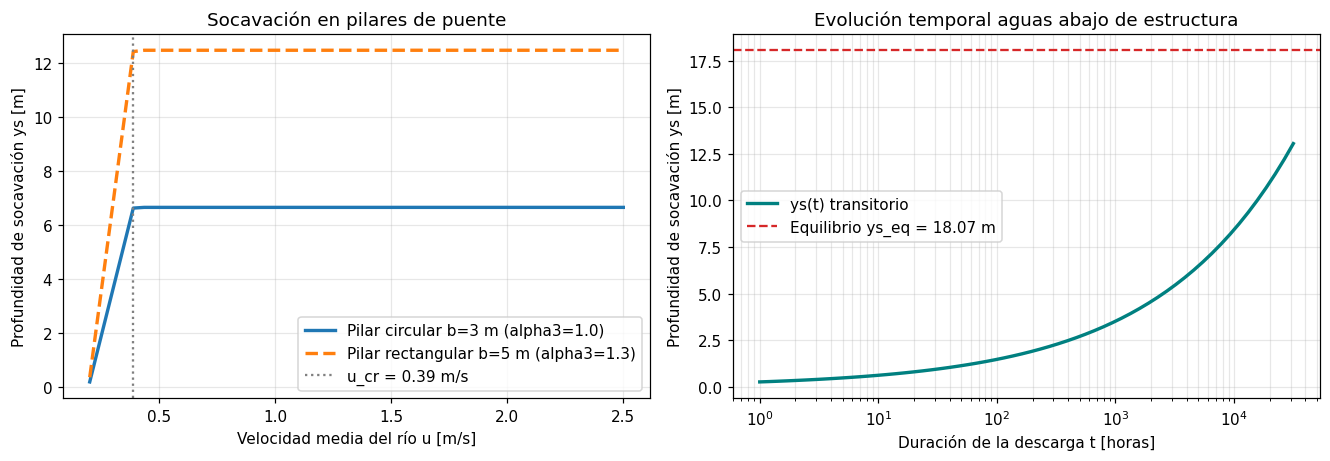

In [2]:
u_vals = np.linspace(0.2, 2.5, 50)
pier_d3 = sm.scour.scour_bridge_pier(
    h0=6.0, pier_width=3.0, d50=0.0003, d90=0.0006, alpha3=1.0, alpha4=1.0, u=u_vals, Hs=0.0
)
pier_d5 = sm.scour.scour_bridge_pier(
    h0=6.0, pier_width=5.0, d50=0.0003, d90=0.0006, alpha3=1.3, alpha4=1.0, u=u_vals, Hs=0.0
)

hours = np.logspace(0, 4.5, 60)
ds_time = sm.scour.scour_downstream_structure(
    h0=5.0, u=1.1, duration_hours=hours, d50=0.00025, d90=0.0005, turbulence_r=0.20
)

u_cr_pier = float(np.asarray(pier_d3.ucr_cw).flat[0])
ys_eq_val = float(np.asarray(ds_time.scour_depth_eq).flat[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.3))

ax1.plot(u_vals, pier_d3.scour_depth, lw=2.2, label="Pilar circular b=3 m (alpha3=1.0)")
ax1.plot(u_vals, pier_d5.scour_depth, "--", lw=2.2, label="Pilar rectangular b=5 m (alpha3=1.3)")
ax1.axvline(u_cr_pier, color="gray", ls=":", label=f"u_cr = {u_cr_pier:.2f} m/s")
ax1.set_xlabel("Velocidad media del río u [m/s]")
ax1.set_ylabel("Profundidad de socavación ys [m]")
ax1.set_title("Socavación en pilares de puente")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.semilogx(hours, ds_time.scour_depth_t, lw=2.2, color="teal", label="ys(t) transitorio")
ax2.axhline(ys_eq_val, color="tab:red", ls="--", label=f"Equilibrio ys_eq = {ys_eq_val:.2f} m")
ax2.set_xlabel("Duración de la descarga t [horas]")
ax2.set_ylabel("Profundidad de socavación ys [m]")
ax2.set_title("Evolución temporal aguas abajo de estructura")
ax2.grid(alpha=0.3, which="both")
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Estructuras Costeras: Pie de Diques, Tuberías y Pilotes bajo Oleaje

Comparamos las fórmulas de **SPM, Fowler, Sato, Yokoyama y Xie** para socavación al pie de muros y escolleras ante alturas de ola de diseño crecientes, y evaluamos la socavación bajo una **tubería submarina** ($D = 1.0\,\text{m}$) bajo corriente, oleaje y régimen combinado.


Pilote vertical (D=1.2 m, Tp=8 s, Hs=[1.0, 2.5, 4.0] m) -> KC=[ 6.39 11.97 17.56] | ys=[0.56 1.13 1.71] m


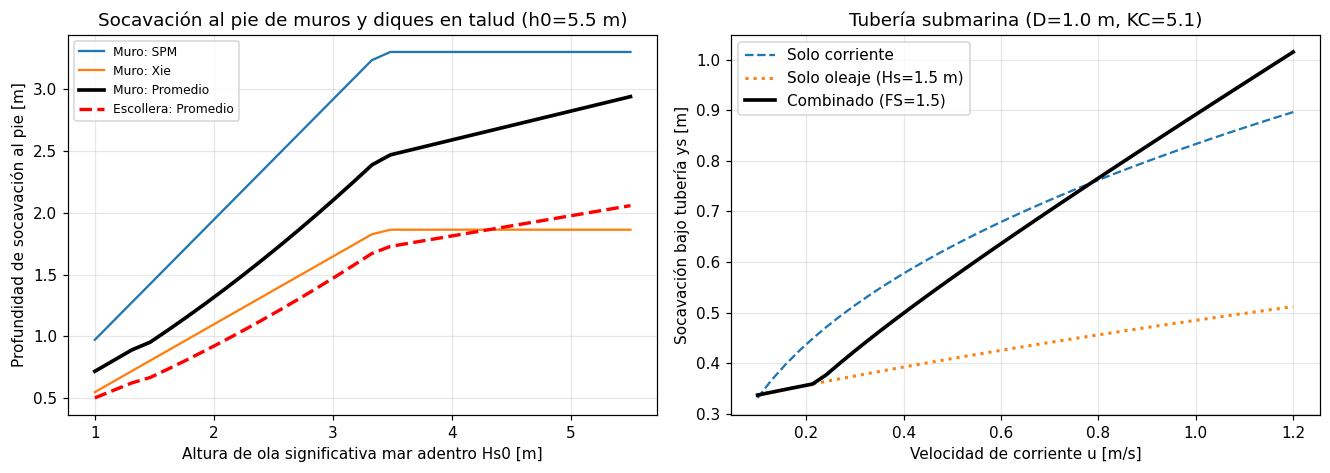

In [3]:
hs0_range = np.linspace(1.0, 5.5, 30)
toe = sm.scour.scour_wall_and_rubblemound_toe(
    h0=5.5, d50=0.00025, d90=0.0005, Hs0=hs0_range, theta0_deg=25.0, Tp=8.0
)

u_pipe = np.linspace(0.1, 1.2, 40)
pipe = sm.scour.scour_horizontal_pipe(
    u=u_pipe, h0=6.0, diameter=1.0, d50=0.00025, Hs=1.5, Tp=6.0, safety_factor=1.5
)
pile = sm.scour.scour_vertical_pile_waves(
    u=0.4, h0=6.0, diameter=1.2, Hs=np.array([1.0, 2.5, 4.0]), Tp=8.0
)
print(f"Pilote vertical (D=1.2 m, Tp=8 s, Hs=[1.0, 2.5, 4.0] m) -> KC={np.round(pile.kc_number, 2)} | ys={np.round(pile.scour_depth, 2)} m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

ax1.plot(hs0_range, toe.wall_spm, label="Muro: SPM")
ax1.plot(hs0_range, toe.wall_xie, label="Muro: Xie")
ax1.plot(hs0_range, toe.wall_average, "k-", lw=2.4, label="Muro: Promedio")
ax1.plot(hs0_range, toe.rubblemound_average, "r--", lw=2.2, label="Escollera: Promedio")
ax1.set_xlabel("Altura de ola significativa mar adentro Hs0 [m]")
ax1.set_ylabel("Profundidad de socavación al pie [m]")
ax1.set_title("Socavación al pie de muros y diques en talud (h0=5.5 m)")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

ax2.plot(u_pipe, pipe.scour_depth_current, "--", label="Solo corriente")
ax2.plot(u_pipe, pipe.scour_depth_waves, ":", lw=2, label="Solo oleaje (Hs=1.5 m)")
ax2.plot(u_pipe, pipe.scour_depth_combined, "k-", lw=2.4, label="Combinado (FS=1.5)")
ax2.set_xlabel("Velocidad de corriente u [m/s]")
ax2.set_ylabel("Socavación bajo tubería ys [m]")
ax2.set_title(f"Tubería submarina (D=1.0 m, KC={float(np.asarray(pipe.kc_number).flat[0]):.1f})")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Compare las 5 formulaciones de `scour_river_groyne` variando el porcentaje de finos cohesivos (`mud_fraction`) de `0.0` a `0.20`.
2. Evalúe con `scour_structure_tip_waves` cómo influye el ancho del morro `structure_width` en la socavación bajo oleaje oblicuo.
